### **Rebuilding DiffusionGemma's Sampler for TPU in PyTorch (Annotated)**

<ins>Project</ins>: TorchTPU Content Sprint<br>
<ins>Author</ins>: Harshal Janjani, Google Developer Expert in AI (MENA)<br>
<ins>GitHub</ins>: https://github.com/harshaljanjani<br>

In [1]:
# @title Licensed under the Apache License, Version 2.0 (the "License")
# Copyright 2026 Harshal Janjani
#
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
#     http://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.
#
# This notebook accompanies the repository
# "DiffusionGemma on TorchTPU"
#
# Project: TorchTPU Content Sprint
# Author: Harshal Janjani, GDE in AI (MENA)
# GitHub: https://github.com/harshaljanjani

### **What if a model wrote 256 tokens at once? 🤔**

Hi, welcome to this tutorial! Almost every language model you've used writes <ins>one token at a time</ins>, left to right. DiffusionGemma, which Google released with open weights in 2026, doesn't. It starts from a block of 256 random tokens (a <ins>canvas</ins>) and cleans up the whole block over a handful of passes, so one pass through the network can settle dozens of tokens instead of one. That sounds like free speed, and on a GPU the published numbers say it nearly is. We're going to find out what it takes to get there on a <ins>TPU</ins>, in plain PyTorch, with [TorchTPU](https://github.com/google-pytorch/torch_tpu).

The plan is the one I'd follow for any piece of inference code on a new accelerator. We take the sampler exactly as Hugging Face Transformers ships it, run it, and then rebuild it one stage at a time, measuring what each stage gets us. Please keep one thing in mind as we go, *not every stage buys speed*. Some buy memory, one buys nothing at all except the right to do the next one, and one of them fixes a wrong answer that no throughput table would ever show. So when a number doesn't move, the first thing to ask is whether we're measuring the right thing.

Please change the runtime type to a <ins>TPU</ins> (v5e or v6e, one chip is enough). Everything here is sized to fit a single chip!

Let's begin 👀

### **Setup (^///^)**

TorchTPU is a PyTorch backend, so the TPU shows up as `torch.device("tpu")` and ordinary PyTorch code runs on it. We pin Transformers, because we're going to read and then replace specific lines of its DiffusionGemma sampler. The last install is the small package this notebook accompanies, [`dgemma_tpu`](https://github.com/harshaljanjani/diffusiongemma-tpu). We'll write the important ideas by hand in the cells below, and use the package for the full sampler once we've understood every piece of it.

In [2]:
import os

# Quiet the libraries before they load; progress bars and advisory warnings only add noise here.
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_VERBOSITY"] = "error"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["TRANSFORMERS_NO_ADVISORY_WARNINGS"] = "1"

import gc, time, logging, warnings
import pandas as pd
import torch
from IPython.display import display
from transformers import AutoConfig, DiffusionGemmaForBlockDiffusion
from transformers.utils import logging as transformers_logging
warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()

MODEL_ID = "google/diffusiongemma-26B-A4B-it"
# The exact commit of the model repo, so a later run reads the same configuration.
REVISION = "main"
DEV = torch.device("tpu")
SEED = 1234
# Two canvases of 256 tokens each.
NEW_TOKENS = 512
PROMPT_TOKENS = 200
TIMED_RUNS = 3

# Every result in this notebook is shown as a table; values are formatted before they get here.
def show_table(rows):
    styled = (
        pd.DataFrame(rows)
        .style.hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    )
    display(styled)

def show_values(values):
    show_table([{"Quantity": name, "Value": value} for name, value in values.items()])

# A PyTorch call on a TPU returns once the work is queued. This waits for the chip to finish.
def sync():
    torch.accelerator.synchronize(DEV)

show_values({
    "Accelerator": str(torch.accelerator.current_accelerator()),
    "Chips visible": torch.accelerator.device_count(),
    "PyTorch": torch.__version__,
})

/opt/dgemma/venv/lib/python3.12/site-packages/torch_tpu/__init__.py:37: UserWarning: <TorchTpu/Performance/TcMalloc/> tcmalloc is not loaded; TorchTPU host performance may be degraded due to glibc ptmalloc contention. Preload libtcmalloc before starting Python (e.g. LD_PRELOAD=/usr/lib/x86_64-linux-gnu/libtcmalloc_minimal.so.4), or set PYTHONWARNINGS="ignore:<TorchTpu/Performance/TcMalloc/" to suppress this warning.
  _tcmalloc_check.check_tcmalloc()


I0000 00:00:1794320092.546073    3833 pjrt_api.cc:119] GetPjrtApi was found for TPU at /opt/dgemma/venv/lib/python3.12/site-packages/libtpu/libtpu.so


Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')I0000 00:00:1794320093.578973    3833 device_rt.cc:166] PjRt runtime initialization deferred for tpu

Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime
I0000 00:00:1794320093.581930    3833 libtpu_version.cc:63] Setting libtpu version to: 0.0.52
/opt/dgemma/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Quantity,Value
Accelerator,tpu
Chips visible,1
PyTorch,2.15.0+cpu


### **What Generating Text by Diffusion Actually Is**

Let's first recall how an ordinary LLM generates. A tokenizer cuts text into tokens (integers that index a fixed vocabulary), the model returns one score per vocabulary entry for the next position, we pick a token, append it, and go again. Those scores are called <ins>logits</ins>, one evaluation of the model is a <ins>forward pass</ins>, and this scheme is called <ins>autoregressive</ins> (AR) generation. *One forward pass, one token.*

A block diffusion model changes what a forward pass is asked to do. It works like this:

1. *Start from noise:* Fill a canvas of 256 positions with tokens drawn uniformly at random from the vocabulary.
2. *Denoise:* Run the network over the whole canvas. For every position it returns logits for what the clean token there should be. This is one <ins>denoising step</ins>.
3. *Accept the confident ones:* Positions where the model is nearly certain keep the token sampled from their logits.
4. *Renoise the rest:* Every other position gets a fresh random token, and we go back to step 2.

After a handful of steps the canvas stops changing, and we move on to the next 256 tokens. Two more details matter for everything that follows. The network has an <ins>encoder</ins> that reads the finished text left to right and stores what later tokens need from it (the KV cache, more on that soon), and a <ins>decoder</ins> that denoises the canvas while reading that store. And each denoising step is handed the previous step's prediction as a hint, which is called <ins>self-conditioning</ins>.

So the trade is this. An AR model needs 256 forward passes for 256 tokens. A diffusion model needs maybe a dozen, but each of those passes carries 256 tokens through the network instead of one. *Whether that is a good trade depends entirely on what a forward pass costs on the hardware in front of us*, and that is what we're here to measure.

### **The Model We'll Use**

The released DiffusionGemma has 25.8 billion weights, about 48 GiB in 16 bit floats, and a single TPU chip has 16 GB (v5e) or 32 GB (v6e) of memory. It doesn't fit, and running it properly takes four chips (the repository does exactly that, but it's not something a free notebook can do).

So we build a <ins>stand-in</ins>. We take the released configuration and keep only 3 of its 30 layers, with random weights. Everything that decides how fast a step runs is unchanged, namely the width of the layers, the 262,144 entry vocabulary, the 128 experts in each layer (more on those at stage 6) and the 256 token canvas. What we give up is the text. *Random weights write gibberish*, and that's fine, because we're studying the loop around the model. We'll check correctness a different way near the end, by comparing tokens against the reference sampler instead of reading them.

In [3]:
config = AutoConfig.from_pretrained(MODEL_ID, revision=REVISION)
text_config = config.text_config
show_values({
    "Layers in the released model": text_config.num_hidden_layers,
    "Hidden size": text_config.hidden_size,
    "Vocabulary": f"{text_config.vocab_size:,}",
    "Experts per layer": text_config.num_experts,
    "Experts used per token": text_config.top_k_experts,
    "Canvas length": config.canvas_length,
    "Sliding window": text_config.sliding_window,
})

# Two sliding window layers and one full attention layer, the two kinds the released model mixes.
text_config.layer_types = ["sliding_attention", "sliding_attention", "full_attention"]
text_config.num_hidden_layers = 3
torch.manual_seed(SEED)
model = DiffusionGemmaForBlockDiffusion(config).to(torch.bfloat16).eval()

distinct_weights = sum({id(p): p.numel() for p in model.parameters()}.values())
listed_weights = sum(p.numel() for _, p in model.named_parameters(remove_duplicate=False))
WEIGHT_BYTES = distinct_weights * 2
show_values({
    "Distinct weights": f"{distinct_weights:,}",
    "Weights if every module's list is summed": f"{listed_weights:,}",
    "Size in bf16 (GiB)": f"{WEIGHT_BYTES / 1024**3:.2f}",
})

Quantity,Value
Layers in the released model,30
Hidden size,2816
Vocabulary,"262,144"
Experts per layer,128
Experts used per token,8
Canvas length,256
Sliding window,1024


I0000 00:00:1794320096.216954    3833 pjrt_api.cc:168] The PJRT plugin has PJRT API version 0.117. The framework PJRT API version is 0.116.
I0000 00:00:1794320097.421774    3833 pjrt_c_api_client.cc:187] PjRtCApiClient created.


Quantity,Value
Distinct weights,"3,765,355,184"
Weights if every module's list is summed,"7,678,270,768"
Size in bf16 (GiB),7.01


Look at the last two counts, they're *off by nearly a factor of two*. That isn't a bug. DiffusionGemma's encoder and decoder are the same layers used in two ways, so every weight is <ins>shared</ins> (tied) between them, and a naive count sees each one twice. Hold on to that, because it is about to matter.

### **[Stage 0, Before We Even Start] Moving the Model to the TPU**

The usual way to put a model on a device is `model.to(device)`. Before doing that to several GiB of weights, let's try it on a toy with the same property, two layers sharing one weight.

In [4]:
class TiedPair(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.first = torch.nn.Linear(4, 4, bias=False)
        self.second = torch.nn.Linear(4, 4, bias=False)
        self.second.weight = self.first.weight  # One weight, two owners

pair = TiedPair()
tied_on_cpu = pair.first.weight is pair.second.weight
pair = pair.to(DEV)
show_values({
    "Shared on the CPU": "Yes" if tied_on_cpu else "No",
    "Shared after .to(tpu)": "Yes" if pair.first.weight is pair.second.weight else "No",
})

Quantity,Value
Shared on the CPU,Yes
Shared after .to(tpu),No


The tie is gone 😬 Each layer now owns a private copy. For our model that means *every encoder weight would be stored twice*, and the released model would need 96 GiB instead of 48. On a GPU `.to` swaps the data underneath each weight and the sharing survives. TPU tensors can't be swapped in place like that, so PyTorch builds a new weight for every owner it meets.

The fix is to do the walk ourselves, move each <ins>distinct</ins> weight exactly once, and hand the moved copy to every module that referred to the original. It's `move_preserving_ties` in [dgemma_tpu/runtime.py](https://github.com/harshaljanjani/diffusiongemma-tpu/blob/main/dgemma_tpu/runtime.py), and the whole idea is the few lines below.

```python
moved = {}
for module in model.modules():
    for name, parameter in module._parameters.items():
        if id(parameter) not in moved:
            moved[id(parameter)] = torch.nn.Parameter(parameter.data.to(device))
        module._parameters[name] = moved[id(parameter)]
```

In [5]:
from dgemma_tpu.runtime import move_preserving_ties

model = move_preserving_ties(model, DEV)
sync()
encoder_layer = model.model.encoder.language_model.layers[0]
decoder_layer = model.model.decoder.layers[0]
show_values({
    "Encoder and decoder still share weights": "Yes" if encoder_layer.experts.gate_up_proj is decoder_layer.experts.gate_up_proj else "No",
    "Weights (GiB)": f"{WEIGHT_BYTES / 1024**3:.2f}",
    "TPU memory in use (GiB)": f"{torch.accelerator.memory_allocated(DEV) / 1024**3:.2f}",
})

Quantity,Value
Encoder and decoder still share weights,Yes
Weights (GiB),7.01
TPU memory in use (GiB),7.01


Memory in use matches the size of the weights. No tokens per second in this stage at all, its unit is *whether the model fits*.

### **What a TPU Wants**

A GPU runs a model as a long stream of small programs (kernels) that Python launches one after another. A TPU prefers something different. Its compiler, XLA, takes a whole function, a full forward pass for example, and turns it into <ins>one program</ins> laid out for the chip. That program is fast, but it is compiled for *exact tensor shapes*, and compiling takes seconds. So the rules of the game are short:

1. *Shapes must not change.* A tensor that grows by one row is a new program and a new compile.
2. *Anything that changes between calls has to live in a tensor.* A Python number that changes is baked into the program, so a new value means a new program too.
3. *Don't ask the chip questions.* Work is queued and runs in the background. The moment Python needs an actual value, say for `if tensor.all():`, it has to stop and wait for everything queued so far. That wait is a <ins>host sync</ins>.

TorchTPU gives us three ways to run the same code, and we'll meet all three. <ins>Strict eager</ins> sends one operation at a time, like a GPU would. <ins>DeferAndFuse</ins> holds operations back and fuses runs of them. And `torch.compile(backend="tpu")` hands XLA a whole function.

### **Meet the Speed Limit**

Before measuring anything, let's work out what the chip could possibly do. To run one forward pass, every weight has to travel from the chip's memory to its arithmetic units at least once, and memory can only be read so fast. That rate is the <ins>memory bandwidth</ins>, and it gives an upper bound no clever code can beat.

$$
\text{Forward Passes per Second} \leq \frac{\text{Memory Bandwidth}}{\text{Model Weight Size}}
$$

For an AR model a forward pass is a token, so this is a ceiling on tokens per second. For us *a forward pass is a denoising step over 256 tokens*, which is the whole reason to be interested. We measure the bandwidth by timing an operation that only reads, `torch.sum` over 1 GiB of floats.

In [6]:
def measure_read_bandwidth(size_mb=1024, iters=20):
    n = (size_mb * 1024 * 1024) // 4
    a = torch.randn(n, device=DEV, dtype=torch.float32)
    for _ in range(5):
        torch.sum(a)
    sync()
    times = []
    for _ in range(iters):
        sync()
        t0 = time.perf_counter()
        torch.sum(a)
        sync()  # Wait for the chip before reading the clock
        times.append(time.perf_counter() - t0)
    times.sort()
    gb_per_s = (a.numel() * 4) / times[len(times) // 2] / 1e9
    del a
    return gb_per_s

BANDWIDTH_GB_S = measure_read_bandwidth()
STEP_CEILING = BANDWIDTH_GB_S * 1e9 / WEIGHT_BYTES
FASTEST_STEP_MS = 1000 / STEP_CEILING
# The released model settles a canvas in about 12 steps; we use that to turn step time into tokens/s.
STEPS_PER_CANVAS = 12
show_values({
    "Measured read bandwidth (GB/s)": f"{BANDWIDTH_GB_S:.1f}",
    "Ceiling (denoising steps/s)": f"{STEP_CEILING:.1f}",
    "Fastest possible step (ms)": f"{FASTEST_STEP_MS:.2f}",
    "Ceiling at 12 steps per canvas (tokens/s)": f"{STEP_CEILING * config.canvas_length / STEPS_PER_CANVAS:.0f}",
})

I0000 00:00:1794320151.653819    4161 compilation_cache_utils.cc:218] Tier-3 compilation cache root directory: 
I0000 00:00:1794320151.653844    4161 tier2_compilation_cache.cc:80] Tier-2 compilation cache is disabled for world size 1.
I0000 00:00:1794320151.653847    4161 tier3_compilation_cache.cc:50] Backup compilation for tier-3 cache read is disabled as tier-3 cache is disabled.


Quantity,Value
Measured read bandwidth (GB/s),1223.8
Ceiling (denoising steps/s),162.5
Fastest possible step (ms),6.15
Ceiling at 12 steps per canvas (tokens/s),3467


Two notes on that table. The clock here includes the time Python takes to send one operation to the chip, so the bandwidth is a slight underestimate (good enough for a back of the envelope bound). And the last row needs a number of steps per canvas, which is a property of the *weights*, not of the hardware. The released model settles a canvas in about 12 steps. Our random stand-in settles whenever its random logits happen to look confident, which tells us nothing. So the honest unit in this notebook is <ins>milliseconds per denoising step</ins>, and whenever a table shows tokens per second it is that step time converted at 12 steps per canvas. Hold on to the fastest possible step; every result below is reported as a share of it.

### **The Measurement Harness**

Timing an accelerator wrongly is surprisingly easy (I've done it more times than I'd like to admit), so three rules.

1. *Warm up, and throw the first run away:* On a TPU the first call pays for compilation, which can be tens of seconds.
2. *Take the median of several runs:* One slow run caused by something unrelated should not move the number.
3. *Synchronize before stopping the clock:* Without `sync()` we'd be timing how fast Python can queue work.

`measure` times a function that returns the generated tokens and the number of denoising steps it ran, divides one by the other, and `report` adds one line to the results table.

In [7]:
def measure(fn, label="", batch=1):
    torch.manual_seed(SEED)
    fn()  # Warmup run, result thrown away; this is where compilation happens
    sync()
    times = []
    for _ in range(TIMED_RUNS):
        sync()
        t0 = time.perf_counter()
        tokens, steps = fn()
        sync()
        times.append(time.perf_counter() - t0)
    times.sort()
    median = times[len(times) // 2]
    ms_per_step = 1000 * median / steps
    return {
        "label": label,
        "batch": batch,
        "median_sec": median,
        "steps": steps,
        "ms_per_step": ms_per_step,
        "tokens_per_sec": batch * config.canvas_length / (STEPS_PER_CANVAS * ms_per_step / 1000),
        "share_of_ceiling": 100 * batch * FASTEST_STEP_MS / ms_per_step,
    }

RESULTS = []

def result_row(r):
    return {
        "Stage": r["label"],
        "Time per step (ms)": f"{r['ms_per_step']:.1f}",
        "Tokens/s at 12 steps per canvas": f"{r['tokens_per_sec']:.0f}",
        "Share of ceiling": f"{r['share_of_ceiling']:.1f}%",
    }

def report(result):
    RESULTS.append(result)
    show_table([result_row(result)])

# The prompt's content does not matter for timing, only its length.
generator = torch.Generator().manual_seed(SEED)
INPUT_IDS = torch.randint(1000, 200_000, (1, PROMPT_TOKENS), generator=generator).to(DEV)
show_values({"Prompt tokens": INPUT_IDS.shape[1], "Tokens to generate": NEW_TOKENS})

Quantity,Value
Prompt tokens,200
Tokens to generate,512


### **One Step by Hand**

Before any loop, let's run a single denoising step ourselves, so we can see each object from the section on diffusion. The encoder reads the prompt into the cache, then the decoder gets a canvas of random tokens.

In [8]:
from transformers import DynamicCache

with torch.no_grad():
    cache = DynamicCache(config=model.config.get_text_config(decoder=True))
    model.model.encoder(input_ids=INPUT_IDS, past_key_values=cache)
    canvas = torch.randint(0, text_config.vocab_size, (1, config.canvas_length), device=DEV)
    logits = model(decoder_input_ids=canvas, past_key_values=cache).logits
    # Entropy measures how spread out a distribution is; 0 means the model is certain.
    entropy = torch.distributions.Categorical(logits=logits).entropy()

show_values({
    "Canvas shape": str(tuple(canvas.shape)),
    "Logits shape": str(tuple(logits.shape)),
    "Logits size (MiB)": f"{logits.numel() * logits.element_size() / 1024**2:.0f}",
    "Lowest entropy on the canvas": f"{float(entropy.min()):.2f}",
    "Entropy of a uniform guess": f"{float(torch.log(torch.tensor(float(text_config.vocab_size)))):.2f}",
})
del cache, logits

Quantity,Value
Canvas shape,"(1, 256)"
Logits shape,"(1, 256, 262144)"
Logits size (MiB),256
Lowest entropy on the canvas,0.02
Entropy of a uniform guess,12.48


The logits have shape `[1, 256, 262144]`, one row of 262,144 scores for each of the 256 canvas positions. That single tensor is *a quarter of a gigabyte*, and the sampler looks at all of it on every step. Remember its size, it comes back at stage 3.

The acceptance rule from the overview can now be stated exactly. Sort the positions from most to least certain, and accept the longest prefix whose entropies, leaving out the largest one, add up to less than a small bound (0.1 for the released model). Tokens that are individually certain are *nearly independent of each other*, so fixing them all in one step costs almost nothing in quality. This is the <ins>entropy bound</ins> sampler, and here it is in five lines.

```python
sorted_entropy, order = torch.sort(entropy, dim=-1)
cumulative = torch.cumsum(sorted_entropy, dim=-1)
accept_sorted = cumulative - sorted_entropy <= entropy_bound
accepted = torch.zeros_like(accept_sorted).scatter(-1, order, accept_sorted)
canvas = torch.where(accepted, sampled_tokens, random_tokens)
```

Every shape in those five lines is fixed. That will turn out to be the exception.

### **[Stage 0] The Sampler as Shipped**

Now the loop, exactly as Transformers ships it. `model.generate` runs the encoder, then denoising steps until the canvas settles or 48 steps pass, then appends the canvas and starts the next one. The returned `tokens_per_forward` tells us how many steps it ran. With no arguments it uses a `DynamicCache`, which grows by concatenation, and runs in strict eager mode.

In [9]:
@torch.no_grad()
def generate_shipped(input_ids, **kwargs):
    out = model.generate(input_ids, max_new_tokens=NEW_TOKENS, pad_token_id=0, **kwargs)
    tokens = out.sequences[:, input_ids.shape[1]:]
    steps = int(round(float(tokens.shape[1] / out.tokens_per_forward.max())))
    return tokens, max(steps, 1)

result = measure(lambda: generate_shipped(INPUT_IDS), label="0. Transformers sampler, eager")
report(result)

Stage,Time per step (ms),Tokens/s at 12 steps per canvas,Share of ceiling
"0. Transformers sampler, eager",52.0,410,11.8%


About a tenth of the ceiling, ouch! Let's count what is happening. Each denoising step is a few hundred separate operations, and in strict eager mode each one is sent to the chip by itself. On top of that the loop asks `if torch.all(finished_denoising): break` after every step ([generation_diffusion_gemma.py, line 789](https://github.com/huggingface/transformers/blob/v5.22.2/src/transformers/models/diffusion_gemma/generation_diffusion_gemma.py#L789)), and each time it asks, Python stops until the chip has caught up. The chip is doing very little arithmetic, *it's mostly waiting for Python*.

### **[Stage 1] Asking Transformers to Compile**

Transformers knows this, and the sampler has a compiled path. Passing `cache_implementation="static"` switches to a preallocated cache and wraps the encoder, the decoder and the sampler in `torch.compile`. Before running it, guess what happens on a TPU (go on, actually make a guess).

In [10]:
try:
    generate_shipped(INPUT_IDS, cache_implementation="static")
    outcome = "Ran"
except Exception as error:
    lines = str(error).strip().splitlines()
    reason = next((line for line in lines if "TypeError" in line), lines[0])
    outcome = f"{type(error).__name__}: {reason.strip()[:160]}"
show_values({"Compiled path of the shipped sampler": outcome})
torch._dynamo.reset()

Quantity,Value
Compiled path of the shipped sampler,BackendCompilerFailed: TypeError: Unexpected keyword arguments: {'mode': 'reduce-overhead'}


It doesn't run at all. The reason is in [`_compile_functions`](https://github.com/huggingface/transformers/blob/v5.22.2/src/transformers/models/diffusion_gemma/generation_diffusion_gemma.py#L1235), which compiles everything with `mode="reduce-overhead"`. That mode means "record a CUDA graph", a GPU feature, and the TPU backend rejects it. The sampler was written around CUDA graphs from top to bottom, down to a call to `torch.compiler.cudagraph_mark_step_begin()` on every step.

So on a TPU we have a slow path that works and a fast path that doesn't start. From here on we build our own, and the first thing it needs is a cache.

### **[Interlude] The Cache, and a Wrong Answer Nobody Would Notice**

In attention, each token is turned into a query (what it is looking for), a key (what it offers to be found by) and a value (what it hands over when found). Finished text never changes, so its keys and values are computed once by the encoder and kept. That store is the <ins>KV cache</ins>, and every denoising step reads it.

Most of DiffusionGemma's layers use <ins>sliding window attention</ins>, where a token looks back over at most 1,024 positions. For those layers the cache only needs to keep the last 1,024 tokens. Transformers has a preallocated cache for this, `StaticCache`, and it has a problem that is worth seeing for ourselves, because *it gives wrong tokens without any error*. We can show it on the CPU with a tiny model whose window is 24 tokens, by generating the same thing with both caches from the same random seed.

In [11]:
from transformers import DiffusionGemmaConfig, DiffusionGemmaTextConfig, Gemma4VisionConfig

def build_tiny(sliding_window):
    torch.manual_seed(0)
    tiny_text = DiffusionGemmaTextConfig(
        vocab_size=512, hidden_size=64, intermediate_size=128, num_hidden_layers=2, num_attention_heads=4,
        num_key_value_heads=2, head_dim=16, sliding_window=sliding_window, max_position_embeddings=1024,
        layer_types=["sliding_attention", "full_attention"], pad_token_id=0, eos_token_id=1, bos_token_id=2,
        num_experts=4, top_k_experts=2, moe_intermediate_size=32,
    )
    tiny_vision = Gemma4VisionConfig(
        hidden_size=32, intermediate_size=64, num_hidden_layers=1, num_attention_heads=2, image_size=32, patch_size=16
    )
    tiny_config = DiffusionGemmaConfig(
        text_config=tiny_text, vision_config=tiny_vision, canvas_length=16,
        boi_token_id=509, eoi_token_id=510, image_token_id=511,
    )
    return DiffusionGemmaForBlockDiffusion(tiny_config).eval()

@torch.no_grad()
def tiny_generate(tiny, ids, cache_implementation):
    torch.manual_seed(1)
    kwargs = {"cache_implementation": cache_implementation} if cache_implementation else {}
    return tiny.generate(ids, max_new_tokens=48, max_denoising_steps=6, disable_compile=True, **kwargs).sequences

tiny_ids = torch.randint(3, 500, (1, 12), generator=torch.Generator().manual_seed(0))
rows = []
for window in (512, 24):
    tiny = build_tiny(window)
    dynamic = tiny_generate(tiny, tiny_ids, None)[0, 12:]
    static = tiny_generate(tiny, tiny_ids, "static")[0, 12:]
    same = (dynamic == static)
    first_difference = "None" if bool(same.all()) else int((~same).nonzero()[0])
    rows.append({
        "Sliding window": window,
        "Matching tokens": f"{int(same.sum())} of {same.numel()}",
        "First differing token": first_difference,
    })
show_table(rows)

Sliding window,Matching tokens,First differing token
512,48 of 48,None
24,35 of 48,17


With a window larger than the text, the two caches agree on every token. With a window of 24 they agree on the first canvas and *then part ways*, right where the cached text (12 prompt tokens plus a 16 token canvas) first exceeds the window.

The cause is two counters. The static sliding window layer keeps its length in a tensor while the window is filling up, and once it is full it switches to a plain Python integer and stops updating the tensor ([cache_utils.py, line 527](https://github.com/huggingface/transformers/blob/v5.22.2/src/transformers/cache_utils.py#L527)). The decoder, meanwhile, decides where to put the canvas by reading the tensor ([`append_to_cache`](https://github.com/huggingface/transformers/blob/v5.22.2/src/transformers/models/diffusion_gemma/modeling_diffusion_gemma.py#L461)). So past the window it writes the canvas at a stale position, *on top of cached tokens*. For the released model that means any request where prompt plus output passes 1,024 tokens.

That Python integer hurts twice, by the way. The compiler treats a changed integer as a different program (rule 2 from earlier), so the same line would also force a recompile for every canvas.

### **[Stage 2] A Cache That Stays Put**

Here is the cache we'll use instead, and it is simple enough to write out. A full attention layer gets a buffer for the longest sequence, and new keys are written at a position held in a tensor. A sliding layer gets a buffer of exactly one window, kept <ins>right aligned</ins>, so that appending is always the same two operations, glue the new keys on the end and keep the last window.

```python
class SlidingAttentionLayer:
    def update(self, key_states, value_states, length):
        keys = torch.cat([self.keys, key_states], dim=2)      # Window, then the new tokens
        self.keys.copy_(keys[:, :, -self.window_length:])     # Keep the last window, in place
        return keys
```

There is no "is it full yet" branch, because an empty window and a full one go through the same code. Which slots hold real tokens is tracked in a boolean tensor that gets shifted the same way, and the attention mask is computed from it. *Nothing about the cache's state lives in Python.* The full version is `BlockDiffusionStaticCache` in [dgemma_tpu/cache.py](https://github.com/harshaljanjani/diffusiongemma-tpu/blob/main/dgemma_tpu/cache.py).

Let's watch one layer of it work on a window of 4.

In [12]:
from dgemma_tpu.cache import SlidingAttentionLayer

layer = SlidingAttentionLayer(window_length=4)
layer.allocate(batch_size=1, num_heads=1, head_dim=1, dtype=torch.float32, device=torch.device("cpu"))
rows = []
next_token = 1
for num_new in (2, 3, 2):
    new = torch.arange(next_token, next_token + num_new, dtype=torch.float32).view(1, 1, num_new, 1)
    visible, _ = layer.update(new, new, length=None)
    rows.append({
        "Tokens appended": str(new.flatten().int().tolist()),
        "What attention sees": str(visible.flatten().int().tolist()),
        "Window afterwards": str(layer.keys.flatten().int().tolist()),
    })
    next_token += num_new
show_table(rows)

Tokens appended,What attention sees,Window afterwards
"[1, 2]","[0, 0, 0, 0, 1, 2]","[0, 0, 1, 2]"
"[3, 4, 5]","[0, 0, 1, 2, 3, 4, 5]","[2, 3, 4, 5]"
"[6, 7]","[2, 3, 4, 5, 6, 7]","[4, 5, 6, 7]"


Zeros are empty slots, which the mask hides. The buffer never changes size and never moves. Expect nothing in tokens per second from this stage by itself (it's a bit of a boring one, sorry); it is the precondition for everything after it.

### **[Stage 3] One Step, One Shape**

Next, the denoising step itself. For XLA to compile it once and reuse it for every step of every canvas, a step has to be a pure function of tensors whose shapes never change. Reading the shipped loop with that in mind, four things stand in the way.

1. *The first step is special.* Self-conditioning has no previous prediction on step one, so the shipped code passes `None`, and a function called with `None` is a different program from one called with a tensor. We pass zeros, which is what `None` meant anyway.
2. *The hint is enormous.* The previous prediction is carried between steps as logits, the quarter gigabyte tensor from earlier, and the decoder then turns it into probabilities and multiplies by the embedding table to get a `[256, 2816]` hint. We do that multiplication at the end of the step and carry the small result. Same arithmetic, moved by one line.
3. *The same normalization runs four times.* The shipped step normalizes the logits once to sample, twice more for two entropies, and once again inside the decoder on the next step. One `log_softmax` can feed all of them.
4. *Finished rows.* In a batch, a row whose canvas has settled must stop changing. The shipped code checks `if finished.any():` in Python, which is a host sync. `torch.where` does the same thing on the chip, with no question asked.

One more substitution. The shipped code samples with `torch.multinomial`. We use the <ins>Gumbel max trick</ins> instead, add noise of a particular shape to the log probabilities and take the largest. It draws from exactly the same distribution, and it's one addition and one `argmax`, both of which XLA fuses into the rest of the step.

```python
gumbel = -torch.log(-torch.log(uniform))
sampled_tokens = torch.argmax(log_probs + gumbel, dim=-1)
```

The step is `_denoise_step_impl` in [dgemma_tpu/generate.py](https://github.com/harshaljanjani/diffusiongemma-tpu/blob/main/dgemma_tpu/generate.py). Let's run the rebuilt loop, still in strict eager mode, with the experts left at the Transformers default so that only the loop has changed.

In [13]:
from dgemma_tpu import StaticBlockDiffusionGenerator
from dgemma_tpu.moe import set_experts_implementation

def make_generator(batch=1, **kwargs):
    static_generator = StaticBlockDiffusionGenerator(
        model, max_new_tokens=NEW_TOKENS, prompt_bucket=PROMPT_TOKENS, pad_token_id=0, **kwargs
    )
    def run(input_ids):
        out = static_generator.generate(input_ids)
        return out.sequences[:, input_ids.shape[1]:], out.num_denoising_steps
    return run

set_experts_implementation(model, "grouped_mm")
eager_static = make_generator(stop_check_interval=1)
result = measure(lambda: eager_static(INPUT_IDS), label="3. Static cache and step, eager")
report(result)

Stage,Time per step (ms),Tokens/s at 12 steps per canvas,Share of ceiling
"3. Static cache and step, eager",57.5,371,10.7%


Throughput is right where it was, huh? We removed three normalizations, a quarter gigabyte tensor and a pile of reallocations, and the step takes the same time. This is the most useful non-result in the notebook. In strict eager mode the chip is fed one operation at a time, and *the time is in the feeding, not in the arithmetic*. Removing arithmetic from a loop that is waiting on Python buys nothing. What we did buy is that *the step now has one shape*, and that is what the next stage cashes in.

### **[Stage 4] One Program per Stage**

Now we hand XLA whole functions. There are four of them, <ins>prefill</ins> (the encoder reads the prompt), the denoising step, a small one that finalizes a canvas, and one that adds a finished canvas to the cache. Each is compiled with `torch.compile(backend="tpu", fullgraph=True, dynamic=False)`. `dynamic=False` says "these shapes are final", and `fullgraph=True` turns any accidental host sync inside a function into an error instead of a silent slowdown.

Before the measurement, let's look at a trap that cost me an afternoon. The temperature (a number that sharpens the model's distribution as the steps go on) differs on each step, so by rule 2 it must be a tensor. The obvious way to get 48 of them is to make one tensor and slice it. Watch what the compiler does with slices.

In [14]:
class CountingBackend:
    """A torch.compile backend that counts programs, then hands them to the TPU backend."""
    def __init__(self):
        self.programs = 0
    def __call__(self, graph_module, example_inputs):
        from torch._dynamo.backends.registry import lookup_backend
        self.programs += 1
        return lookup_backend("tpu")(graph_module, example_inputs)

def scale(x, temperature):
    return x / temperature

x = torch.ones(8, device=DEV)
rows = []
for name, make in [
    ("Slices of one tensor", lambda: list(torch.linspace(0.4, 0.8, 6, device=DEV).unbind(0))),
    ("One tensor per value", lambda: [torch.tensor(v, device=DEV) for v in torch.linspace(0.4, 0.8, 6).tolist()]),
]:
    torch._dynamo.reset()
    backend = CountingBackend()
    compiled = torch.compile(scale, backend=backend, dynamic=False)
    for temperature in make():
        compiled(x, temperature)
    sync()
    rows.append({"How the six temperatures are made": name, "Programs compiled": backend.programs})
torch._dynamo.reset()
show_table(rows)

How the six temperatures are made,Programs compiled
Slices of one tensor,6
One tensor per value,1


Six slices, six programs. A slice remembers *where in its parent tensor it starts*, the TPU backend treats that offset as part of the input's identity, and so every slice looks like a new kind of input. Giving each value a tensor of its own brings it back to one program. On the CPU both versions compile once, so no local test would have caught this (ask me how I know).

With that out of the way, the measurement.

In [15]:
set_experts_implementation(model, "grouped_mm")
compiled_static = make_generator(stop_check_interval=1, compile_backend="tpu")
t0 = time.perf_counter()
compiled_static(INPUT_IDS)
sync()
first_call = time.perf_counter() - t0
result = measure(lambda: compiled_static(INPUT_IDS), label="4. + torch.compile(backend='tpu')")
report(result)
show_values({"First call, including compilation (s)": f"{first_call:.0f}"})

Stage,Time per step (ms),Tokens/s at 12 steps per canvas,Share of ceiling
4. + torch.compile(backend='tpu'),15.6,1363,39.3%


Quantity,Value
"First call, including compilation (s)",27


Nearly four times faster, on the same arithmetic and the same hardware. The first call takes tens of seconds because XLA is compiling, and every call after it reuses the four programs. In a server that cost is paid once at startup.

What about DeferAndFuse, the middle mode? It needs an environment variable set before the process starts, so we can't flip it inside a notebook. Measured separately on a v6e chip with a deeper version of this model, it lands between the two, about 2.3 times faster than strict eager and about 1.6 times slower than compiled. It's a real option when a function can't be compiled yet.

### **[Stage 5] Asking the Chip Fewer Questions**

One host sync per step is still in the loop, the check for whether every row has settled. We can't remove it entirely, since stopping early is the whole reason the released model needs 12 steps instead of 48. But nothing says we must ask after *every* step. If we ask every fourth step, the worst case is three wasted steps on a canvas, and rows that settled earlier are frozen on the chip in the meantime, so the answer is unchanged. Before running, guess how much a sync costs.

In [16]:
rows = []
for interval, name in [(1, "Every step"), (4, "Every 4 steps"), (0, "Never")]:
    run = make_generator(stop_check_interval=interval, compile_backend="tpu")
    r = measure(lambda: run(INPUT_IDS), label=f"5. Stop check: {name.lower()}")
    rows.append({"Stop check": name, "Time per step (ms)": f"{r['ms_per_step']:.2f}"})
    if interval == 4:
        report(r)
show_table(rows)

Stage,Time per step (ms),Tokens/s at 12 steps per canvas,Share of ceiling
5. Stop check: every 4 steps,15.9,1338,38.6%


Stop check,Time per step (ms)
Every step,15.66
Every 4 steps,15.95
Never,15.70


Nothing we can measure, and that's the honest result. A sync costs a fraction of a millisecond, against a step of many milliseconds, so the three rows differ by less than the noise between runs. The interval would matter for a small model, where a step is so short that the wait dominates. What does matter enormously is *having* the check. On the released model, switching adaptive stopping off entirely takes two canvases from 28 steps to 96, which cuts tokens per second to a third. I keep the interval at 4 from here on. Sometimes the right thing to report about an optimization is that *it doesn't matter here*, and why.

### **[Stage 6] The Experts**

So where is the time going? To answer that we need the one part of the architecture we've skipped. Each layer of this model has 128 small feed-forward networks called <ins>experts</ins>, and a router sends every token to just 8 of them. This is a <ins>mixture of experts</ins> (MoE), and it is why the model is called "26B-A4B", 26 billion weights of which about 4 billion are active for any one token. The experts hold about 88% of all the weights.

How should "send each token to its 8 experts" be computed? There are three natural ways.

1. *Group:* Sort the (token, expert) pairs by expert, then do one matrix multiplication per group. This is the Transformers default, `grouped_mm`.
2. *Gather:* For each token, copy out the weights of its 8 experts, then multiply. This is `batched_mm`.
3. *Just run everything:* Push every token through all 128 experts with two big batched multiplications, then keep only the 8 results each token asked for. This throws away 15 of every 16 results, which sounds silly.

Let's time one layer each way, for a single token (what an AR model sends) and for a 256 token canvas.

In [17]:
from dgemma_tpu.moe import DENSE_PREWEIGHTED_EXPERTS, TOKEN_COUNT_EXPERTS, register_experts_implementations

register_experts_implementations()
experts = model.model.decoder.layers[0].experts
names = {"grouped_mm": "Group", "batched_mm": "Gather", DENSE_PREWEIGHTED_EXPERTS: "Run everything"}
rows = []
for num_tokens in (1, 256):
    hidden = torch.randn(num_tokens, text_config.hidden_size, device=DEV, dtype=torch.bfloat16)
    scores = torch.rand(num_tokens, text_config.num_experts, device=DEV)
    weights, index = torch.topk(scores, text_config.top_k_experts, dim=-1)
    row = {"Tokens in the pass": num_tokens}
    for implementation, name in names.items():
        text_config._experts_implementation = implementation
        torch._dynamo.reset()
        try:
            forward = torch.compile(experts.forward, backend="tpu", fullgraph=True, dynamic=False)
            with torch.no_grad():
                forward(hidden, index, weights)
                sync()
                t0 = time.perf_counter()
                for _ in range(20):
                    forward(hidden, index, weights)
                sync()
            row[f"{name} (ms)"] = f"{(time.perf_counter() - t0) / 20 * 1000:.2f}"
        except Exception as error:
            row[f"{name} (ms)"] = "Out of memory" if "memory" in str(error).lower() else "Failed"
    rows.append(row)
torch._dynamo.reset()
show_table(rows)

Tokens in the pass,Group (ms),Gather (ms),Run everything (ms)
1,3.09,0.13,1.31
256,3.43,64.97,1.38


Three things to read off the table (this is my favourite table in the notebook).

1. *The default costs the same for 1 token as for 256.* Its time is not arithmetic, it's bookkeeping. A profile of the step shows the chip copying the layer's entire expert tensor into a different layout, about a gigabyte, plus a handful of slow gathers, on every single call.
2. *For one token, gathering wins by a mile.* Copying out 8 small matrices is nearly free.
3. *For a canvas, the silly option wins.* A TPU is built around a very large matrix multiplier, and two big dense multiplications with nothing to sort or gather are exactly what it is fast at. Doing sixteen times the arithmetic beats doing the bookkeeping.

So the right implementation depends on <ins>how many tokens are in the pass</ins>, and that count is a shape, which is known when the program is compiled. We can simply choose at compile time; gather for a few tokens, run everything up to about 1,500, group beyond that. That's `token_count_experts_forward` in [dgemma_tpu/moe.py](https://github.com/harshaljanjani/diffusiongemma-tpu/blob/main/dgemma_tpu/moe.py).

In [18]:
set_experts_implementation(model, TOKEN_COUNT_EXPERTS)
best = make_generator(stop_check_interval=4, compile_backend="tpu")
result = measure(lambda: best(INPUT_IDS), label="6. + experts chosen by token count")
report(result)

Stage,Time per step (ms),Tokens/s at 12 steps per canvas,Share of ceiling
6. + experts chosen by token count,9.7,2189,63.1%


More than a third off the time per step from changing how one layer type multiplies, with the model and its output untouched. There's a second lesson in that table, and it's about fairness. The same default slows an AR model down far more than it slows us, since an AR pass has one token and the default charges it the full price. On a deeper version of this model the fix makes AR decoding 7.7 times faster and diffusion 1.7 times faster. *Had we benchmarked diffusion against AR with the default experts, diffusion would have looked several times better than it deserves.* When you compare two things, make sure both got your best effort.

### **Did We Change the Answer?**

Of course, speed means nothing if the tokens changed! We rewrote the cache, the step, the sampling and the experts, so this deserves a real test. Sampling is random, which makes "same tokens" tricky, but both samplers draw their randomness from PyTorch's generator. If we make the reference draw its samples with the same Gumbel trick, and seed both the same way, they consume the same random numbers in the same order and *must* produce identical tokens. We run it on the CPU with the tiny model, on a prompt long enough to pass the sliding window, against the reference with its dynamic cache (the one that is correct).

In [19]:
from dgemma_tpu.sampler import gumbel_max_sample

def reference_tokens(tiny, ids):
    original = torch.multinomial
    # The reference sampler, drawing through the same Gumbel trick as ours.
    torch.multinomial = lambda probs, num_samples=1, **kw: gumbel_max_sample(
        torch.log(probs), torch.rand(probs.shape)
    ).unsqueeze(-1)
    try:
        torch.manual_seed(3)
        return tiny.generate(
            ids, max_new_tokens=64, max_denoising_steps=8, disable_compile=True, eos_token_id=1, pad_token_id=0
        ).sequences
    finally:
        torch.multinomial = original

rows = []
for window in (512, 24, 8):
    tiny = build_tiny(window)
    reference = reference_tokens(tiny, tiny_ids)
    ours_generator = StaticBlockDiffusionGenerator(
        tiny, max_new_tokens=64, prompt_bucket=16, stop_check_interval=1,
        max_denoising_steps=8, eos_token_id=1, pad_token_id=0,
    )
    torch.manual_seed(3)
    ours = ours_generator.generate(tiny_ids).sequences
    rows.append({
        "Sliding window": window,
        "Matching tokens": f"{int((ours == reference).sum())} of {reference.numel()}",
    })
show_table(rows)

Sliding window,Matching tokens
512,76 of 76
24,76 of 76
8,76 of 76


Every token agrees, including with windows far shorter than the text, the case the static cache got wrong in the interlude. Note that the prompt here is 12 tokens and our sampler pads it to 16 on the left (prompts are padded up to a fixed <ins>bucket</ins> so that prefill compiles once per bucket instead of once per length), so this also checks that padding changes nothing. *Keep a test like this next to any sampler you rewrite.* A cache that reads the wrong slots still produces fluent looking text at full speed, and a throughput table will never tell you.

### **[Stage 7] Batching**

So far everything served one request. Now we run 8 canvases in the same pass. Each weight still travels from memory once per step, and when it arrives it is multiplied against 8 times as many tokens. Before running, two guesses. From batch 1 to batch 8, what happens to total tokens per second, and how much longer does a step take?

In [20]:
table, sweep = [], {}
for batch in (1, 2, 4, 8):
    ids = INPUT_IDS.repeat(batch, 1)
    run = make_generator(stop_check_interval=4, compile_backend="tpu")
    try:
        r = measure(lambda: run(ids), label=f"7. Batch {batch}", batch=batch)
    except Exception as error:
        table.append({"Batch": batch, "Time per step (ms)": "Out of memory", "Tokens/s at 12 steps per canvas": "", "Share of ceiling": ""})
        break
    sweep[batch] = r
    table.append({
        "Batch": batch,
        "Time per step (ms)": f"{r['ms_per_step']:.1f}",
        "Tokens/s at 12 steps per canvas": f"{r['tokens_per_sec']:.0f}",
        "Share of ceiling": f"{r['share_of_ceiling']:.0f}%",
    })
    del run
    gc.collect()
show_table(table)
largest = max(sweep)
RESULTS.append(sweep[largest])
show_values({
    f"Throughput, batch 1 to {largest}": f"{sweep[largest]['tokens_per_sec'] / sweep[1]['tokens_per_sec']:.1f}x",
    f"Time per step, batch 1 to {largest}": f"{sweep[largest]['ms_per_step'] / sweep[1]['ms_per_step']:.1f}x",
})

Batch,Time per step (ms),Tokens/s at 12 steps per canvas,Share of ceiling
1,9.7,2192,63%
2,13.8,3081,89%
4,22.3,3825,110%
8,41.8,4079,118%


Quantity,Value
"Throughput, batch 1 to 8",1.9x
"Time per step, batch 1 to 8",4.3x


The share of the ceiling passes 100%, and that is not a measurement error! The ceiling assumed that one read of the weights serves one canvas, and here one read serves eight. Throughput grows with the batch, but well short of 8 times, and it's worth being clear about why, because it is *different from the AR story*. An AR model at a batch of one is starved, a pass does almost no arithmetic for all the weights it reads, so batching is nearly free. A diffusion step already carries 256 tokens, which is to say *it arrived pre-batched*. The chip was already busy, so 8 canvases cost real time. Two things grow with the batch here, the experts (2,048 tokens is past the point where running everything is cheapest) and the vocabulary sized tensors, 67 million scores per canvas per step.

This is the trade the DiffusionGemma report describes from the other side. At low concurrency diffusion is far ahead, and somewhere in the tens of concurrent requests AR catches up, because AR had more idle hardware to give back. The repository measures exactly that with the released weights on four chips; diffusion is 5.2 times faster than autoregressive Gemma 4 at a batch of one, and the two meet at around a batch of 16.

### **Summary**

In [21]:
baseline = RESULTS[0]["ms_per_step"]
show_table([{**result_row(r), "Step speedup over shipped": f"{baseline / r['ms_per_step']:.1f}x"} for r in RESULTS[:-1]])

Stage,Time per step (ms),Tokens/s at 12 steps per canvas,Share of ceiling,Step speedup over shipped
"0. Transformers sampler, eager",52.0,410,11.8%,1.0x
"3. Static cache and step, eager",57.5,371,10.7%,0.9x
4. + torch.compile(backend='tpu'),15.6,1363,39.3%,3.3x
5. Stop check: every 4 steps,15.9,1338,38.6%,3.3x
6. + experts chosen by token count,9.7,2189,63.1%,5.3x


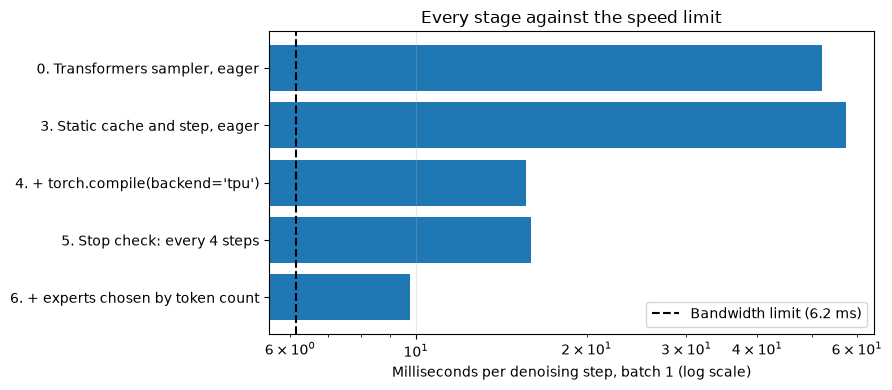

In [22]:
import matplotlib.pyplot as plt

labels = [r["label"] for r in RESULTS[:-1]]
step_ms = [r["ms_per_step"] for r in RESULTS[:-1]]
plt.figure(figsize=(9, 4))
plt.barh(labels[::-1], step_ms[::-1], color="tab:blue")
plt.axvline(FASTEST_STEP_MS, ls="--", c="black", label=f"Bandwidth limit ({FASTEST_STEP_MS:.1f} ms)")
plt.xscale("log")
plt.xlabel("Milliseconds per denoising step, batch 1 (log scale)")
plt.title("Every stage against the speed limit")
plt.legend(loc="lower right")
plt.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

### **What to Take Away**

Notice how unevenly the gains were spread. Compiling and the experts account for all of the speedup. The static cache and the one-shape step bought no speed by themselves and made compiling possible. The stop check interval bought nothing we could measure. Moving the model without breaking its ties bought no speed at all and decided whether the model fits. And the interlude changed no number in any table, it changed *the answer*. Judged by tokens per second alone, half of this notebook would look like wasted effort, which is exactly the trap I warned about at the start.

The rules we collected are short, and none of them is specific to diffusion.

1. *Whatever changes between calls has to live in a tensor,* and not in a slice of one either.
2. *One function, one shape.* If the first call is special, pad it until it isn't.
3. *Don't ask the chip questions you can batch up.*
4. *Measure the building blocks at the sizes you'll actually use.* The best expert implementation for 1 token was the worst for 256.
5. *Check the tokens.* Twice.

A few things we left out. The released 26B model doesn't fit one chip, and the repository runs it on four by slicing every expert across the chips and adding the pieces back together with one all-reduce per layer. The repository also has the same treatment for autoregressive Gemma 4, the model DiffusionGemma was fine-tuned from, so that the two can be compared on the same hardware with both at their best. And several of the surprises here (the compiled path that doesn't start, the static cache past the window, the lost ties, the default experts) are written up in its `upstream/` folder as reports for Transformers and TorchTPU.

Thanks for sticking around till the end! 🙌